# Evidencia final: uso, procesamiento y visualización de grandes volúmenes de datos

**Estimación del área de humo en imágenes mediante PySpark y MLlib**

**Autor:** Jacob Espejel Guiza · **Matrícula:** A01712021  
**Institución:** Tecnológico de Monterrey, Campus Querétaro  
**Modalidad:** individual · **Módulo 6: Big Data**

[Repositorio del proyecto](https://github.com/Vacones/Evidencias_BigData) · [Evidencia en GitHub](https://github.com/Vacones/Evidencias_BigData/blob/main/Individual/A01712021/A01712021_Jacob%20Espejel%20Guiza_Evidencia.ipynb) · [Colab](https://colab.research.google.com/drive/1UN2_JtPT-s6vtRF6u6VITHAAnNA61-rm) · [Dashboard Tableau Public](https://public.tableau.com/app/profile/jacob.espejel/viz/Libro4_17940038331000/SMOKEResultados)

Este proyecto integra el procesamiento de un dataset original de **3.118 GB**, la extracción de características visuales con Spark, un **Pipeline de MLlib** con Random Forest, **validación cruzada de tres folds**, evaluación sobre un conjunto de prueba independiente y un dashboard publicado en Tableau Public. Las explicaciones se presentan junto a los resultados que sustentan cada etapa.


## Resumen ejecutivo y objetivos

Se estudió el problema de estimar la proporción de una imagen ocupada por cajas anotadas como humo. El objetivo es una regresión entre 0 y 1; no se trata de clasificar fotografías, detectar nuevas cajas ni estimar una concentración física de humo. El dataset seleccionado fue [Smoke Fire Detection YOLO](https://www.kaggle.com/datasets/sayedgamal99/smoke-fire-detection-yolo), cuya descarga conserva una estructura de imágenes y etiquetas D-Fire.

El inventario registró **21,527 imágenes** y **3,118,334,084 bytes** de imágenes y etiquetas. Después de excluir 26 etiquetas inválidas, se trabajó con **21,501 registros**: 14,109 de entrenamiento, 3,098 de validación y 4,294 de prueba. Cada imagen se representó mediante 144 características visuales. Las anotaciones YOLO se utilizaron exclusivamente para construir la respuesta y auditar los datos, evitando incorporarlas como predictores.

El Pipeline `VectorAssembler → RandomForestRegressor` comparó dos profundidades con CrossValidator. Se seleccionó profundidad 10, con 60 árboles. En test se obtuvo **MAE 9.75 pp**, **RMSE 15.43 pp** y **R² 0.4733**; la reducción relativa del RMSE frente al promedio de entrenamiento fue **27.43%**. El tablero sintetiza la composición de los datos y los errores del modelo para valorar su utilidad y reconocer sus limitaciones.

Los objetivos específicos fueron verificar el volumen original, auditar las anotaciones, procesar las imágenes sin cargar su contenido completo en pandas, entrenar y seleccionar el modelo con herramientas de MLlib, contrastarlo con un baseline y comunicar resultados mediante evidencia ejecutada y visualización administrada.

**Alcance de la evidencia.** Las salidas de código conservadas pertenecen a la ejecución registrada el 6 de noviembre de 2026. El procesamiento se realizó en una VM de Colab con Spark local, no en un clúster multinodo. La extracción original de características y la reanudación auditada desde Parquet se distinguen explícitamente en la sección 4.


## 1. Ambiente de procesamiento

Se utilizó PySpark 4.0.5 con Java 17 y Python 3.13.18 en CPU. El controlador y los workers Python comparten el ejecutable configurado en `PYSPARK_PYTHON`. Antes del procesamiento se verificó, mediante una prueba aislada, la comunicación Python–Java, el uso de vectores de 144 valores y la escritura y lectura de Parquet. Sus ocho registros diagnósticos no se mezclan con los datos del proyecto.

La sesión usa `local[2]`, 4 GB configurados para el controlador y ocho particiones de shuffle. Esta configuración limita el trabajo concurrente a los recursos de una sola VM y mantiene el costo de planificación acorde con el tamaño de las características derivadas.


In [1]:
import os, sys, subprocess, shutil, json, platform, time, textwrap, importlib.metadata
from pathlib import Path
SPARK_VERSION = '4.0.5'
if 'pyspark' in sys.modules and sys.modules['pyspark'].__version__ != SPARK_VERSION:
    raise RuntimeError('Reinicia la sesión de Colab antes de ejecutar esta configuración de Spark.')
subprocess.run(['apt-get','update','-qq'], check=True, stdout=subprocess.DEVNULL)
subprocess.run(['apt-get','install','-y','-qq','openjdk-17-jre-headless'], check=True, stdout=subprocess.DEVNULL)
subprocess.run([sys.executable,'-m','pip','install','-q',f'pyspark=={SPARK_VERSION}',
                'numpy<3','pandas>=2,<3','pyarrow>=15,<20','pillow','kagglehub','pyyaml','matplotlib'], check=True)
java_roots = sorted(Path('/usr/lib/jvm').glob('java-17-openjdk-*'))
assert java_roots, 'No se encontró Java 17'
os.environ['JAVA_HOME'] = str(java_roots[0])
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
os.environ['DISABLE_COLAB_CACHE'] = 'true'
os.environ.pop('SPARK_HOME', None)
# Prueba técnica aislada: Python worker -> VectorUDT -> Parquet -> lectura.
# Sus ocho filas de diagnóstico NO se mezclan con los datos ni métricas del proyecto.
probe_code = r"""
import tempfile, shutil
from pyspark.sql import SparkSession, types as T
from pyspark.ml.linalg import Vectors, VectorUDT
s = SparkSession.builder.master('local[2]').appName('SmokeSparkProbe').config('spark.driver.memory','1g').getOrCreate()
s.sparkContext.setLogLevel('ERROR')
p = tempfile.mkdtemp(prefix='spark_probe_')
try:
    schema = T.StructType([T.StructField('id',T.IntegerType()), T.StructField('features',VectorUDT())])
    rdd = s.sparkContext.parallelize(range(8),2).map(lambda i:(i,Vectors.dense([float(i)]*144)))
    s.createDataFrame(rdd,schema).write.mode('overwrite').parquet(p+'/test')
    loaded = s.read.parquet(p+'/test')
    assert loaded.count()==8 and len(loaded.first().features)==144
    print('PRUEBA_TECNICA_OK: workers Python, vectores de 144 valores y escritura/lectura Parquet.')
finally:
    s.stop(); shutil.rmtree(p,ignore_errors=True)
"""
print('Verificando comunicación Python-Java y Parquet antes de procesar el dataset...', flush=True)
try:
    probe = subprocess.run([sys.executable,'-c',probe_code], capture_output=True, text=True, timeout=120)
except subprocess.TimeoutExpired as exc:
    raise RuntimeError('La prueba técnica de Spark excedió 120 s. Reinicia la sesión antes de continuar; no ejecutes el dataset completo.') from exc
if probe.returncode:
    print(probe.stdout); print(probe.stderr[-6000:])
    raise RuntimeError('Falló la prueba técnica de Spark. No se inicia el procesamiento grande.')
print(probe.stdout.strip(), flush=True)
from pyspark.sql import SparkSession, functions as F, types as T, Window
spark = (SparkSession.builder.master('local[2]').appName('SmokeBigData')
         .config('spark.driver.memory','4g').config('spark.sql.shuffle.partitions','8')
         .config('spark.sql.files.maxPartitionBytes',128*1024*1024)
         .config('spark.python.worker.reuse','true')
         .config('spark.ui.showConsoleProgress','true').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
assert spark.version == SPARK_VERSION
RUN = Path('/content/smoke_resultados'); RUN.mkdir(exist_ok=True, parents=True)
started = time.time()
print('Python',platform.python_version(),'Spark',spark.version,'Java',os.environ['JAVA_HOME'],flush=True)
assert spark.range(10).groupBy().sum().first()[0] == 45


Verificando comunicación Python-Java y Parquet antes de procesar el dataset...
PRUEBA_TECNICA_OK: workers Python, vectores de 144 valores y escritura/lectura Parquet.
Python 3.13.18 Spark 4.0.5 Java /usr/lib/jvm/java-17-openjdk-amd64


### Análisis: ambiente y alcance del paralelismo

La salida confirma Python 3.13.18, Spark 4.0.5 y Java 17. La prueba aislada de workers, vectores y Parquet terminó correctamente antes del dataset. Sus ocho registros son exclusivamente diagnósticos y no participan en el entrenamiento ni en las métricas.

`local[2]` permite hasta dos hilos de tareas de Spark en **una sola VM**. Ocho particiones no significan ocho máquinas ni ocho tareas simultáneas: se programan según los recursos disponibles. Los workers Python realizan el procesamiento de las particiones de imágenes; la lectura de anotaciones y del inventario usa Python en el controlador. El `Pipeline` aprendido incluye VectorAssembler y RandomForestRegressor; la extracción visual previa es otra etapa del flujo ETL, no un transformador guardado dentro de ese PipelineModel.


## 2. Dataset, procedencia y volumen

El dataset contiene imágenes de humo, fuego y escenas negativas con anotaciones YOLO. Se identificaron las carpetas de imágenes y etiquetas, se contaron los archivos y se sumaron sus tamaños reales. El criterio de volumen considera los originales, no los CSV resumidos ni el tamaño de la representación numérica utilizada para modelar.

La descarga con kagglehub se dirige al almacenamiento local de la VM. La fuente se mantiene identificada por su nombre en Kaggle, y `volumen.json` registra el inventario. El umbral de control es 1,000,000,000 bytes: no se agregan copias artificiales para alcanzarlo.


In [7]:
# Descargar a disco local evita leer miles de archivos desde el montaje remoto.
os.environ['DISABLE_COLAB_CACHE'] = 'true'
LOCAL_ZIP = ''  # Ejemplo: '/content/drive/MyDrive/smoke-fire-detection-yolo.zip'
DATASET = 'sayedgamal99/smoke-fire-detection-yolo'
MIN_BYTES = 1_000_000_000  # 1 GB decimal. 1 GiB equivale a 1,073,741,824 bytes.
assert shutil.disk_usage('/content').free >= 12*1024**3, 'Libera al menos 12 GiB; podría requerirse más según la versión'
if LOCAL_ZIP:
    import zipfile
    root = Path('/content/smoke_dataset'); root.mkdir(exist_ok=True)
    with zipfile.ZipFile(LOCAL_ZIP) as z:
        for name in z.namelist():
            assert (root/name).resolve().is_relative_to(root.resolve()), 'Ruta ZIP insegura'
        z.extractall(root)
else:
    import kagglehub
    try:
        root = Path(kagglehub.dataset_download(DATASET))
    except Exception as exc:
        raise RuntimeError('Descarga no completada. Usa kagglehub.login() y reejecuta, o LOCAL_ZIP con tu descarga oficial.') from exc
extensions = {'.jpg','.jpeg','.png','.bmp','.webp'}
image_paths = sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in extensions
                     and any(x.lower()=='images' for x in p.parts))
assert image_paths, f'No se hallaron imágenes dentro de carpetas images en {root}; revisa la estructura'
image_bytes = sum(p.stat().st_size for p in image_paths)
label_bytes = sum(p.stat().st_size for p in root.rglob('*.txt') if 'labels' in [x.lower() for x in p.parts])
volume = {'dataset':DATASET,'download_path':str(root),'images':len(image_paths),
          'image_bytes':image_bytes,'label_bytes':label_bytes,'raw_bytes':image_bytes+label_bytes,
          'raw_GB':(image_bytes+label_bytes)/1e9,'raw_GiB':(image_bytes+label_bytes)/1024**3}
(RUN/'volumen.json').write_text(json.dumps(volume,indent=2))
print(json.dumps(volume,indent=2))
assert image_bytes+label_bytes >= MIN_BYTES, ('Esta descarga NO cumple 1 GB. Detén la entrega y revisa la versión completa; '
                                           'no se puede afirmar que cumple ni duplicar registros para simular volumen.')

{
  "dataset": "sayedgamal99/smoke-fire-detection-yolo",
  "download_path": "/root/.cache/kagglehub/datasets/sayedgamal99/smoke-fire-detection-yolo/versions/1",
  "images": 21527,
  "image_bytes": 3116477841,
  "label_bytes": 1856243,
  "raw_bytes": 3118334084,
  "raw_GB": 3.118334084,
  "raw_GiB": 2.90417492762208
}


### Análisis: evidencia del volumen original

El inventario registra **21,527 imágenes**, 3,116,477,841 bytes de imágenes y 1,856,243 bytes de etiquetas. La suma es **3,118,334,084 bytes: 3.118 GB decimales o 2.904 GiB**, por encima del requisito de 1 GB. No se agregaron duplicados ni imágenes sintéticas para aumentar el tamaño.

El menor tamaño de las características y de los CSV no contradice ese volumen: son representaciones derivadas del dataset original. `DISABLE_COLAB_CACHE=true` solicita la descarga al disco local para evitar depender del acceso repetido al montaje remoto. Esta es una decisión de implementación; no se dispone de un experimento controlado que cuantifique cuánto acelera el proceso.


## 3. Preparación y calidad de las etiquetas

La configuración YAML identifica las clases reales de la descarga: humo y fuego. Se validan identificadores enteros, cinco campos por anotación, valores finitos y coordenadas normalizadas. Una etiqueta vacía representa una imagen negativa; una etiqueta ausente se trata como incidencia de calidad.

Para cada caja de humo, las coordenadas centrales y sus dimensiones se convierten en límites de rectángulos. La respuesta se define como:

$$y=\frac{\operatorname{área}(\bigcup_i B_i^{\mathrm{humo}})}{\operatorname{área}(I)}.$$

El área de la unión se obtiene mediante un barrido horizontal de intervalos, de modo que las intersecciones entre cajas no se cuenten dos veces. La respuesta está entre 0 y 1; por ejemplo, 0.25 representa el 25% del marco. Las anotaciones inválidas se excluyen y sus motivos se documentan.


In [8]:
import yaml
CLASS_NAMES_OVERRIDE = None  # Ejemplo verificado por ti: {0:'smoke',1:'fire'}
MISSING_LABELS_ARE_NEGATIVE = False
class_candidates = []
for p in list(root.rglob('*.yaml')) + list(root.rglob('*.yml')):
    obj = yaml.safe_load(p.read_text())
    if isinstance(obj,dict) and isinstance(obj.get('names'),(dict,list)):
        names = obj['names']
        names = dict(enumerate(names)) if isinstance(names,list) else {int(k):str(v) for k,v in names.items()}
        class_candidates.append((str(p),names))
if CLASS_NAMES_OVERRIDE is not None:
    class_names = {int(k):str(v) for k,v in CLASS_NAMES_OVERRIDE.items()}
else:
    assert class_candidates, 'No hay YAML de clases. Verifica los IDs y configura CLASS_NAMES_OVERRIDE.'
    assert all(n==class_candidates[0][1] for _,n in class_candidates), 'YAML contradictorios: especifica un mapa verificado'
    class_names = class_candidates[0][1]
smoke_ids = [k for k,v in class_names.items() if v.strip().lower() in {'smoke','humo'}]
assert len(smoke_ids)==1, f'Identificación de humo ambigua: {class_names}'
smoke_id = smoke_ids[0]
assert len(class_names)==2 and any(v.strip().lower() in {'fire','fuego'} for v in class_names.values()), class_names
print('Clases verificadas:',class_names,'ID humo:',smoke_id)

Clases verificadas: {0: 'smoke', 1: 'fire'} ID humo: 0


In [9]:
# Funciones reutilizables incluidas para que el notebook sea autónomo
import math
from pathlib import Path

def union_area(boxes):
    """Área exacta de la unión de rectángulos normalizados; no duplica traslapes."""
    if not boxes:
        return 0.0
    xs = sorted({b[0] for b in boxes} | {b[2] for b in boxes})
    area = 0.0
    for left, right in zip(xs, xs[1:]):
        spans = sorted((y0, y1) for x0,y0,x1,y1 in boxes if x0 < right and x1 > left)
        height, end = 0.0, -1.0
        for lo, hi in spans:
            height += max(0.0, hi-max(lo,end))
            end = max(end, hi)
        area += (right-left)*height
    return min(1.0, max(0.0, area))

def parse_labels(text, smoke_id, known_ids):
    smoke, fire, boxes = 0, 0, []
    for line_no, line in enumerate(text.splitlines(), 1):
        if not line.strip():
            continue
        fields = line.split()
        if len(fields) != 5:
            raise ValueError(f'Línea {line_no}: se esperan 5 campos YOLO, hay {len(fields)}')
        cid_f, cx, cy, w, h = map(float, fields)
        if not all(math.isfinite(x) for x in [cid_f,cx,cy,w,h]):
            raise ValueError('Valores no finitos')
        cid = int(cid_f)
        if cid != cid_f or cid not in known_ids:
            raise ValueError(f'Clase inválida: {cid_f}')
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < w <= 1 and 0 < h <= 1):
            raise ValueError('Coordenadas YOLO fuera de rango')
        # Pequeñas salidas del borde se recortan al marco de la imagen.
        box = (max(0.,cx-w/2), max(0.,cy-h/2), min(1.,cx+w/2), min(1.,cy+h/2))
        if cid == smoke_id:
            smoke += 1
            boxes.append(box)
        else:
            fire += 1
    return union_area(boxes), smoke, fire

def label_path(image_path):
    p = Path(image_path)
    parts = list(p.parts)
    indices = [i for i,v in enumerate(parts) if v.lower() == 'images']
    if not indices:
        raise ValueError(f'No hay directorio images en {p}')
    parts[indices[-1]] = 'labels'
    return Path(*parts).with_suffix('.txt')

def source_split(path):
    parts = {v.lower() for v in Path(path).parts[:-1]}
    if parts & {'test','testing'}: return 'test'
    if parts & {'val','valid','validation'}: return 'val'
    if parts & {'train','training'}: return 'train'
    return 'unspecified'

def feature_names():
    names = []
    for y in range(4):
        for x in range(4):
            names += [f'grid_{y}_{x}_{stat}_{c}' for stat in ['mean','std'] for c in ['r','g','b']]
            names += [f'grid_{y}_{x}_edge']
    names += [f'global_{stat}_{c}' for stat in ['mean','std'] for c in ['r','g','b']]
    names += ['gray_mean','gray_std']
    names += [f'hsv_{c}_bin_{b}' for c in ['h','s','v'] for b in range(8)]
    return names

def image_features(content):
    # Imports locales: funciones de etiquetas y pruebas no requieren Pillow ni numpy.
    import io
    import numpy as np
    from PIL import Image, ImageOps
    with Image.open(io.BytesIO(content)) as raw:
        # No se rota por EXIF: las etiquetas corresponden al marco de píxeles original.
        image = raw.convert('RGB').resize((128,128), Image.Resampling.BILINEAR)
        a = np.asarray(image, dtype=np.float32)/255.
        hsv = np.asarray(image.convert('HSV'), dtype=np.float32)/255.
    values = []
    for y in range(4):
        for x in range(4):
            tile = a[y*32:(y+1)*32, x*32:(x+1)*32]
            values.extend(tile.mean(axis=(0,1)).tolist())
            values.extend(tile.std(axis=(0,1)).tolist())
            gray = tile.mean(axis=2)
            values.append(float((np.abs(np.diff(gray,axis=0)).mean()+np.abs(np.diff(gray,axis=1)).mean())/2))
    values.extend(a.mean(axis=(0,1)).tolist())
    values.extend(a.std(axis=(0,1)).tolist())
    gray = a.mean(axis=2)
    values += [float(gray.mean()),float(gray.std())]
    for c in range(3):
        hist, _ = np.histogram(hsv[:,:,c], bins=8, range=(0,1))
        values.extend((hist/hist.sum()).tolist())
    assert len(values) == len(feature_names())
    return [float(v) for v in values]

In [10]:
import csv
annotations, issues = [], []
for p in image_paths:
    try:
        lp = label_path(p)
        if not lp.exists() and not MISSING_LABELS_ARE_NEGATIVE:
            raise ValueError('Etiqueta ausente; no se presume imagen negativa')
        text = lp.read_text() if lp.exists() else ''
        target, n_smoke, n_fire = parse_labels(text,smoke_id,set(class_names))
        annotations.append((str(p.resolve()),source_split(p),float(target),n_smoke,n_fire))
    except Exception as exc:
        issues.append({'image_path':str(p),'error':str(exc)})
with (RUN/'etiquetas_excluidas.csv').open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=['image_path','error']); w.writeheader(); w.writerows(issues)
print('Etiquetas válidas:',len(annotations),'Exclusiones:',len(issues))
assert len(annotations)>=100, 'Muy pocos registros válidos; revisa etiquetas y carpetas'
assert len(issues)/len(image_paths) <= .05, 'Más de 5% de etiquetas inválidas. Revisa etiquetas_excluidas.csv antes de continuar'
schema = 'image_path string, original_split string, label double, n_smoke int, n_fire int'
labels = spark.createDataFrame(annotations,schema)
labels.groupBy('original_split').count().show()
labels.select('label').summary().show()

Etiquetas válidas: 21501 Exclusiones: 26
+--------------+-----+
|original_split|count|
+--------------+-----+
|          test| 4294|
|         train|14109|
|           val| 3098|
+--------------+-----+

+-------+-------------------+
|summary|              label|
+-------+-------------------+
|  count|              21501|
|   mean|0.12405295822342693|
| stddev|0.21467625978170052|
|    min|                0.0|
|    25%|                0.0|
|    50%|                0.0|
|    75%|0.17933238636363633|
|    max| 0.9917686631944446|
+-------+-------------------+



### Análisis: calidad y definición de la respuesta

La auditoría conservó **21,501 etiquetas válidas** y excluyó **26**. Las exclusiones quedan en `etiquetas_excluidas.csv`. El objetivo es la fracción de imagen cubierta por la **unión de cajas de humo**: los traslapes no se cuentan dos veces. Una etiqueta vacía representa un negativo; una ausente se excluye salvo confirmación expresa del origen.

Las coordenadas YOLO, las clases y los conteos sirven para calcular y auditar el objetivo, pero **no son predictores**. Usarlos como entradas produciría fuga de información. El regresor recibe 144 características obtenidas de los píxeles; no predice una concentración física, una máscara exacta ni coordenadas nuevas de detección.


## 4. Procesamiento de imágenes y representación visual

La extracción completa usa `binaryFile` para leer los bytes de imágenes y `mapPartitions` para procesar los registros de cada partición. Cada fotografía se convierte a RGB y se reduce a 128 × 128 píxeles. Una cuadrícula de 4 × 4 regiones permite obtener estadísticas regionales de color, variación y bordes; se añaden estadísticas globales e histogramas HSV hasta formar **144 características**.

Las características, rutas, tamaños, hashes y errores de decodificación se almacenan en Parquet. En la ejecución que respalda esta evidencia se recuperó el Parquet de la extracción original: se verificó el SHA-256 del respaldo y se compararon inventario, rutas, tamaños y conteos antes de compactarlo. La salida indica esa procedencia y no se interpreta como una nueva decodificación de todas las imágenes.

La escritura materializa las transformaciones de Spark y el resultado persistido evita repetir trabajo entre consultas. Los controles posteriores verifican el volumen representado y los duplicados exactos, y unen las características con las etiquetas válidas.


In [11]:
from urllib.parse import urlparse, unquote
from pyspark.ml.linalg import Vectors, VectorUDT
from pyspark import StorageLevel
# Reanudar desde el Parquet de la ejecución original, si se cargó su respaldo.
# El ZIP conserva las mismas características, archivos y esquema Spark; no son datos simulados.
checkpoint_zip = Path('/content/checkpoint_features_original.zip')
if checkpoint_zip.exists():
    import zipfile, hashlib
    assert hashlib.sha256(checkpoint_zip.read_bytes()).hexdigest() == 'e0665386eadc59df18ab216c8e4abeeaa78379a3da8fbb0bbb90b5cf0e5a925e', 'Respaldo de características distinto del verificado'
    assert DATASET == 'sayedgamal99/smoke-fire-detection-yolo' and volume['raw_bytes'] == 3118334084
    restore_root = Path('/content/restauracion_features')
    restore_root.mkdir(exist_ok=True)
    with zipfile.ZipFile(checkpoint_zip) as z:
        for name in z.namelist():
            assert (restore_root/name).resolve().is_relative_to(restore_root.resolve())
        z.extractall(restore_root)
    restored = restore_root/'features_audit_original.parquet'
    checkpoint_df = spark.read.parquet(str(restored))
    inventory = spark.createDataFrame([(str(p.resolve()), int(p.stat().st_size)) for p in image_paths], 'image_path string, image_bytes long')
    assert checkpoint_df.count() == len(image_paths)
    assert checkpoint_df.select('image_path','image_bytes').exceptAll(inventory).count() == 0
    assert inventory.exceptAll(checkpoint_df.select('image_path','image_bytes')).count() == 0
    target = RUN/'features_audit.parquet'
    compact = RUN/'features_audit_next.parquet'
    print('Compactando el respaldo en ocho particiones...', flush=True)
    checkpoint_df.coalesce(8).write.mode('overwrite').parquet(str(compact))
    check = spark.read.parquet(str(compact))
    assert check.count() == len(image_paths)
    assert check.agg(F.sum('image_bytes')).first()[0] == image_bytes
    if target.exists():
        shutil.rmtree(target)  # Sólo después de verificar el nuevo Parquet; el respaldo original se conserva.
    compact.rename(target)
    feature_origin = 'Parquet auditado de la ejecución original; ZIP SHA-256 verificado y cotejado con el inventario actual'
    print('REANUDACIÓN:', feature_origin, flush=True)
else:
    image_roots = sorted({str(next(parent for parent in p.parents if parent.name.lower()=='images').resolve()) for p in image_paths})
    binary = (spark.read.format('binaryFile').option('recursiveFileLookup','true').load(image_roots)
              .filter(F.lower(F.col('path')).rlike(r'\.(jpg|jpeg|png|bmp|webp)$')))
    def extract_partition(rows):
        import hashlib
        for row in rows:
            path = unquote(urlparse(row.path).path)
            try:
                values = image_features(row.content)
                yield (path,hashlib.sha256(row.content).hexdigest(),int(row.length),Vectors.dense(values),None)
            except Exception as exc:
                yield (path,None,int(row.length),None,str(exc)[:500])
    fschema = T.StructType([T.StructField('image_path',T.StringType()),T.StructField('sha256',T.StringType()),
        T.StructField('image_bytes',T.LongType()),T.StructField('features',VectorUDT()),T.StructField('decode_error',T.StringType())])
    extracted = spark.createDataFrame(binary.select('path','length','content').coalesce(8).rdd.mapPartitions(extract_partition),fschema)
    print('Extrayendo características con 8 tareas Python; espera a que finalice...', flush=True)
    extracted.write.mode('overwrite').parquet(str(RUN/'features_audit.parquet'))
    feature_origin = 'Extracción de píxeles en esta sesión mediante Spark binaryFile'
extracted = spark.read.parquet(str(RUN/'features_audit.parquet')).persist(StorageLevel.MEMORY_AND_DISK)
decode_errors = extracted.filter('decode_error is not null')
decode_errors.select('image_path','decode_error').toPandas().to_csv(RUN/'imagenes_excluidas.csv',index=False)
read_bytes = extracted.agg(F.sum('image_bytes')).first()[0]
assert extracted.count()==len(image_paths), 'El inventario de Spark no coincide con los archivos de imágenes'
print('Bytes originales de imágenes representadas:',read_bytes, '| Origen:',feature_origin)
assert read_bytes==image_bytes
df = extracted.filter('decode_error is null').join(labels,'image_path','inner')
assert df.count()>=100, 'Revisa errores de decodificación y rutas'
# Una misma imagen con etiquetas contradictorias se considera problema de calidad.
conflicts = df.groupBy('sha256').agg(F.min('label').alias('lo'),F.max('label').alias('hi')).filter('hi-lo>0.000001')
assert conflicts.count()==0, 'Hay duplicados exactos con etiquetas contradictorias; corrige el origen'
before = df.count()
priority = F.when(F.col('original_split')=='test',0).when(F.col('original_split')=='val',1).otherwise(2)
win = Window.partitionBy('sha256').orderBy(priority,F.col('image_path'))
df = df.withColumn('_rank',F.row_number().over(win)).filter('_rank=1').drop('_rank')
after = df.count()
print('Duplicados exactos retirados:',before-after)

Compactando el respaldo en ocho particiones...
REANUDACIÓN: Parquet auditado de la ejecución original; ZIP SHA-256 verificado y cotejado con el inventario actual
Bytes originales de imágenes representadas: 3116477841 | Origen: Parquet auditado de la ejecución original; ZIP SHA-256 verificado y cotejado con el inventario actual
Duplicados exactos retirados: 0


### Análisis: cómo se controla el costo del procesamiento

La salida indica **REANUDACIÓN desde el Parquet auditado**: se verificó el SHA-256 del ZIP y se cotejaron rutas, tamaños y conteos contra las imágenes presentes. Se compactó el respaldo y quedaron representados **3,116,477,841 bytes de imágenes**. No se registraron errores de decodificación ni duplicados exactos retirados. Esta ejecución no vuelve a extraer todos los píxeles: el respaldo procede de la extracción original.

En una ejecución sin respaldo, `binaryFile` lee imágenes y `mapPartitions` las procesa con un iterador; `coalesce(8)` limita las particiones antes de los workers para reducir la sobrecarga de miles de tareas pequeñas. Reducir particiones también puede limitar el paralelismo o dejar tamaños desiguales; ocho es una configuración para esta VM, no un óptimo universal. Parquet conserva características y auditoría para reutilizarlas sin repetir la decodificación.

`persist(MEMORY_AND_DISK)` permite reutilizar resultados entre acciones; si no caben en memoria pueden almacenarse en disco. Spark evalúa las transformaciones de forma diferida: acciones como `count`, `first` y `write.parquet` disparan cómputo. Por eso una espera en la escritura puede incluir extracción y transformación, no solo escritura física.

**Límites de la evidencia de eficiencia.** Las anotaciones se recorren secuencialmente en el controlador; `join`, agregaciones y la ventana por hash pueden requerir shuffle. Se usa `toPandas()` para resúmenes, errores y vectores derivados pequeños, no para llevar los 3.118 GB de imágenes al controlador. Las 4,294 predicciones y los 2,000 pares del tablero complementario caben en esta escala; esa exportación necesitaría otro diseño si crecieran. Los registros de tiempo no permiten cuantificar una aceleración frente a otra configuración.


## 5. Separación de datos y prevención de fuga

Se conservaron las particiones oficiales de entrenamiento, validación y prueba. La revisión de duplicados exactos se efectuó por SHA-256 antes de utilizar las particiones en el modelado. El test no participa en la selección de hiperparámetros ni en el cálculo de la media del baseline.

El subconjunto train se utiliza para los folds de CrossValidator. La validación oficial se conserva como comprobación independiente; test se utiliza para la evaluación final. Esta separación controla la fuga directa, aunque no garantiza independencia entre escenas visualmente semejantes sin metadatos de cámara o secuencia.


In [12]:
sources = {r.original_split for r in df.select('original_split').distinct().collect()}
bucket = F.pmod(F.xxhash64('sha256'),F.lit(100))
if {'train','test'} <= sources:
    assert sources <= {'train','val','test'}, 'Hay imágenes sin partición junto a splits oficiales; revisa estructura'
    split_expr = F.col('original_split') if 'val' in sources else (
        F.when(F.col('original_split')=='test','test').when(bucket<20,'val').otherwise('train'))
    split_method = 'Particiones oficiales; validación derivada del train si no existe'
else:
    split_expr = F.when(bucket<70,'train').when(bucket<85,'val').otherwise('test')
    split_method = 'Hash SHA256 70/15/15; sin partición oficial completa'
df = df.withColumn('split',split_expr).persist(StorageLevel.MEMORY_AND_DISK)
df.groupBy('split').agg(F.count('*').alias('n'),F.avg('label').alias('area_promedio')).show()
train, val, test = [df.filter(F.col('split')==s) for s in ['train','val','test']]
counts = {s:df.filter(F.col('split')==s).count() for s in ['train','val','test']}
assert min(counts.values())>=20, f'Particiones insuficientes: {counts}'
assert train.select('label').distinct().count()>1, 'La variable objetivo no tiene variación'
assert val.select('label').distinct().count()>1 and test.select('label').distinct().count()>1

+-----+-----+-------------------+
|split|    n|      area_promedio|
+-----+-----+-------------------+
| test| 4294| 0.1205432875120178|
|  val| 3098|0.12966855147916245|
|train|14109|0.12388805767260955|
+-----+-----+-------------------+



### Análisis: particiones y riesgo de fuga entre escenas

Se conservaron las particiones oficiales: **14,109 train**, **3,098 validación** y **4,294 test**. La selección de parámetros utiliza solo train; validación es una comprobación independiente y test se reserva para la evaluación final.

La revisión por SHA-256 detecta archivos exactamente iguales, no escenas casi idénticas. Sin identificadores confiables de cámara, video o secuencia no puede garantizarse independencia entre escenas. Para evaluar despliegue se requiere separar por esos grupos y usar datos externos; los resultados actuales no demuestran generalización a cualquier cámara.


### 5.1. Exploración del entrenamiento

Las gráficas describen únicamente los datos de train. La composición por categorías y el histograma del objetivo permiten reconocer el desbalance antes del ajuste y justifican la comparación con un predictor constante y la evaluación por subgrupos.


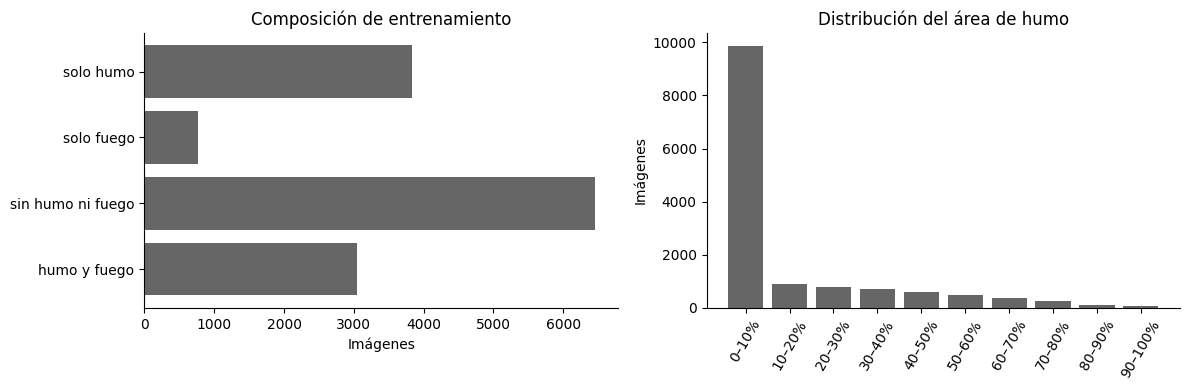

Predominan las áreas pequeñas y las imágenes sin humo; se necesita comparar contra un baseline.


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams.update({'axes.spines.top':False, 'axes.spines.right':False})
eda_summary = (train.withColumn('categoria', F.when((F.col('n_smoke')>0)&(F.col('n_fire')>0),'humo y fuego')
    .when(F.col('n_smoke')>0,'solo humo').when(F.col('n_fire')>0,'solo fuego').otherwise('sin humo ni fuego'))
    .groupBy('categoria').count().orderBy('categoria').toPandas())
eda_hist = train.withColumn('intervalo', F.least(F.lit(9), F.floor(F.col('label')*10)).cast('int')).groupBy('intervalo').count().orderBy('intervalo').toPandas()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(eda_summary['categoria'], eda_summary['count'], color='0.4')
axes[0].set(title='Composición de entrenamiento', xlabel='Imágenes')
axes[1].bar(eda_hist['intervalo'], eda_hist['count'], color='0.4')
axes[1].set_xticks(range(10), [f'{i*10}–{(i+1)*10}%' for i in range(10)], rotation=60)
axes[1].set(title='Distribución del área de humo', ylabel='Imágenes')
plt.tight_layout(); plt.savefig(RUN/'datos.png', dpi=150); plt.show()
print('Predominan las áreas pequeñas y las imágenes sin humo; se necesita comparar contra un baseline.')


### Interpretación de las gráficas de entrenamiento

Hay **3,051** imágenes con humo y fuego, **3,830** solo con humo, **770** solo con fuego y **6,458** sin ambos. Las dos últimas categorías suman **7,228 objetivos cero**. El histograma concentra registros en áreas pequeñas; un buen promedio global podría ocultar errores en las escenas con humo.

Por esa razón se compara el bosque con un baseline que predice la media de train, y se evalúan por separado los casos con y sin humo. Estas gráficas describen exclusivamente train y se colocan antes de la elección del modelo para justificar esas decisiones.


## 6. Pipeline de MLlib y validación cruzada

Se eligió Random Forest porque aprende relaciones no lineales entre características numéricas y una respuesta continua sin requerir una red neuronal. Cada árbol realiza particiones por umbrales y el promedio de sus salidas produce la estimación. La estandarización no es un requisito para esas particiones.

El Pipeline integra `VectorAssembler` y `RandomForestRegressor`. El ensamblador conserva la estructura de entrada durante ajuste y predicción; el regresor utiliza 60 árboles, `maxBins=32`, `minInstancesPerNode=5` y semilla 42. La extracción visual es una etapa previa del ETL y no forma parte del PipelineModel guardado.

`CrossValidator` compara profundidades 5 y 10 mediante tres folds deterministas dentro de train. Se realizan seis ajustes de validación y un reajuste final de la configuración seleccionada sobre todo train. El criterio es el menor RMSE promedio de los folds. La desviación de los resultados expresa variación entre folds y no un intervalo de confianza.


Pipeline: ['VectorAssembler', 'RandomForestRegressor']
Cross validation: 3 folds; 2 configuraciones; 6 ajustes + reajuste final.


,cv_fold,count
0,0,4692
1,1,4702
2,2,4715


,model,depth,rmse_cv_mean,rmse_cv_std
0,RandomForest_depth_5,5,0.176210,0.001815
1,RandomForest_depth_10,10,0.153971,0.001331


Seleccionado por CV: RandomForest_depth_10
Comprobación en validación oficial: {'rmse': 0.15369248041219477, 'mae': 0.09853863886842373, 'r2': 0.49882775781259237}


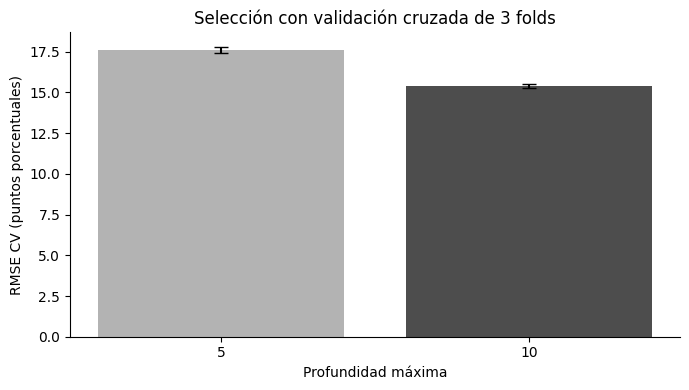

DataFrame[image_path: string, sha256: string, image_bytes: bigint, features: vector, decode_error: string, original_split: string, label: double, n_smoke: int, n_fire: int, split: string, cv_fold: int]

In [14]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def evaluate(predictions):
    return {m: float(RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName=m).evaluate(predictions))
            for m in ['rmse', 'mae', 'r2']}

assembler = VectorAssembler(inputCols=['features'], outputCol='features_ml', handleInvalid='error')
rf = RandomForestRegressor(labelCol='label', featuresCol='features_ml', numTrees=60,
                           maxBins=32, minInstancesPerNode=5, seed=42)
pipeline = Pipeline(stages=[assembler, rf])
param_grid = ParamGridBuilder().addGrid(rf.maxDepth, [5, 10]).build()
cv_train = train.withColumn('cv_fold', F.pmod(F.xxhash64('sha256'), F.lit(3)).cast('int')).cache()
fold_counts = cv_train.groupBy('cv_fold').count().orderBy('cv_fold').toPandas()
assert len(fold_counts) == 3 and fold_counts['count'].min() > 0
print('Pipeline:', [type(stage).__name__ for stage in pipeline.getStages()], flush=True)
print('Cross validation: 3 folds; 2 configuraciones; 6 ajustes + reajuste final.', flush=True)
display(fold_counts)
cv = CrossValidator(estimator=pipeline, estimatorParamMaps=param_grid,
                    evaluator=RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='rmse'),
                    numFolds=3, foldCol='cv_fold', seed=42, parallelism=1, collectSubModels=False)
cv_model = cv.fit(cv_train)
model = cv_model.bestModel
rf_model = model.stages[-1]
selection = [{'model': f'RandomForest_depth_{params[rf.maxDepth]}', 'depth': int(params[rf.maxDepth]),
              'rmse_cv_mean': float(cv_model.avgMetrics[i]), 'rmse_cv_std': float(cv_model.stdMetrics[i])}
             for i, params in enumerate(param_grid)]
best_i = int(np.argmin(cv_model.avgMetrics))
assert rf_model.getMaxDepth() == selection[best_i]['depth']
mean_train = float(train.agg(F.avg('label')).first()[0])
baseline_val = evaluate(val.withColumn('prediction', F.lit(mean_train)))
validation_check = evaluate(model.transform(val))
cv_results = pd.DataFrame(selection)
cv_results.to_csv(RUN/'cross_validation.csv', index=False)
pd.DataFrame([{'model': 'Baseline_media_train', **baseline_val},
              {'model': selection[best_i]['model'], **validation_check}]).to_csv(RUN/'validacion.csv', index=False)
fold_counts.to_csv(RUN/'cv_folds.csv', index=False)
display(cv_results)
print('Seleccionado por CV:', selection[best_i]['model'], flush=True)
print('Comprobación en validación oficial:', validation_check, flush=True)
model.write().overwrite().save(str(RUN/'pipeline_random_forest'))
rf_model.write().overwrite().save(str(RUN/'modelo_random_forest'))
cv_model.write().overwrite().save(str(RUN/'cross_validator_model'))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cv_results['depth'].astype(str), cv_results['rmse_cv_mean']*100,
       yerr=cv_results['rmse_cv_std']*100, capsize=5, color=['0.7', '0.3'])
ax.set(xlabel='Profundidad máxima', ylabel='RMSE CV (puntos porcentuales)', title='Selección con validación cruzada de 3 folds')
plt.tight_layout(); plt.savefig(RUN/'cross_validation.png', dpi=150); plt.show()
cv_train.unpersist()


### Análisis: selección con cross validation

Se eligió Random Forest por su capacidad de aprender relaciones no lineales con características numéricas y producir una respuesta continua al promediar árboles. No requiere estandarización obligatoria para sus particiones por umbrales. VectorAssembler prepara el vector de entrada con la misma estructura durante ajuste y predicción.

Los tres folds contienen **4,692, 4,702 y 4,715 registros**. Con dos profundidades se realizan **seis ajustes de validación y un reajuste final** sobre todo train. Profundidad 5 obtuvo RMSE medio **0.176210**, con desviación **0.001815**; profundidad 10 obtuvo **0.153971**, con desviación **0.001331**. Se seleccionó profundidad 10 por el menor RMSE medio. Esa desviación refleja variación entre folds, no un intervalo de confianza ni una exactitud de clasificación.

En validación oficial se obtuvo RMSE **0.153692**, MAE **0.098539** y R² **0.498828**. Estas métricas no sustituyen a test. `parallelism=1` evita ejecutar varios candidatos de CV al mismo tiempo en la VM; los trabajos internos de Spark siguen usando sus tareas disponibles. `cache()` reutiliza train entre ajustes y `collectSubModels=False` evita conservar todos los submodelos. La búsqueda se limita a dos configuraciones por costo computacional; no se afirma que sean los mejores hiperparámetros posibles.


## 7. Evaluación final y predicciones sobre test

`RegressionEvaluator` calcula MAE, RMSE y R² sobre las 4,294 imágenes reservadas. El baseline predice la media de la respuesta calculada exclusivamente en train. MAE resume el error absoluto medio; RMSE penaliza más los errores grandes; R² compara el error cuadrático residual con la variación del objetivo.

MAE y RMSE se multiplican por 100 para expresarse en puntos porcentuales de área. También se calculan errores por imágenes con y sin humo, se conservan predicciones individuales y se presentan ejemplos junto a la dispersión del área real frente a la estimada.


,model,split,rmse,mae,r2
0,Baseline_media_train,test,0.212679,0.164194,-0.000247
1,RandomForest_depth_10,test,0.154336,0.097519,0.473269


Mejora de RMSE frente al baseline (%): 27.432750760054237


,image_path,label,prediction,abs_error
0,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.000000,0.056579,0.056579
1,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.230208,0.179135,0.051073
2,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.000000,0.127722,0.127722
3,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.121036,0.104099,0.016937
4,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.000000,0.145829,0.145829
5,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.000000,0.007399,0.007399
6,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.000000,0.233163,0.233163
7,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.613854,0.314164,0.299690
8,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.003532,0.008618,0.005086
9,/root/.cache/kagglehub/datasets/sayedgamal99/s...,0.000000,0.007328,0.007328


,feature,importance
77,grid_2_3_mean_r,0.054982
6,grid_0_0_edge,0.044129
70,grid_2_2_mean_r,0.031020
63,grid_2_1_mean_r,0.028895
5,grid_0_0_std_b,0.024645
48,grid_1_2_edge,0.023205
44,grid_1_2_mean_b,0.022870
117,global_std_b,0.022327
136,hsv_v_bin_0,0.017812
66,grid_2_1_std_r,0.014660


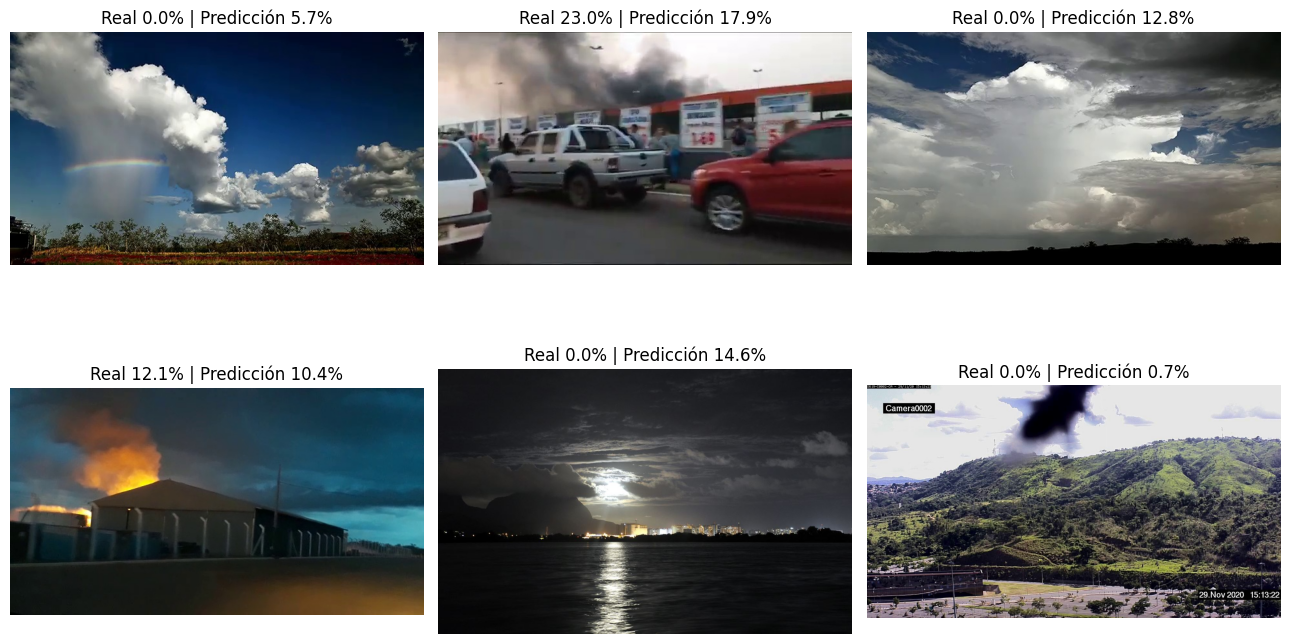

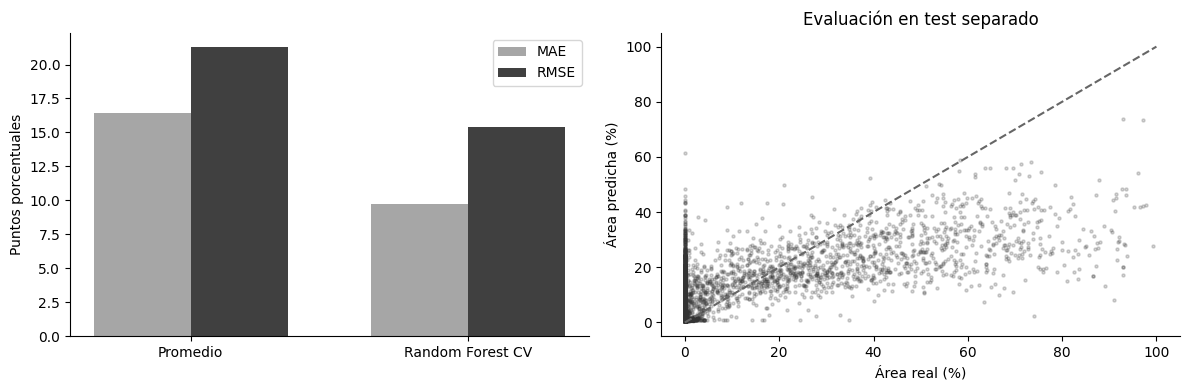

In [15]:
pred = model.transform(test).withColumn('abs_error',F.abs(F.col('prediction')-F.col('label'))).cache()
baseline_test = test.withColumn('prediction',F.lit(mean_train))
scores = evaluate(pred); base_scores = evaluate(baseline_test)
gain = 100*(base_scores['rmse']-scores['rmse'])/base_scores['rmse'] if base_scores['rmse'] else None
rows = [{'model':'Baseline_media_train','split':'test',**base_scores},
        {'model':selection[best_i]['model'],'split':'test',**scores}]
pd.DataFrame(rows).to_csv(RUN/'metricas_test.csv',index=False)
display(pd.DataFrame(rows))
print('Mejora de RMSE frente al baseline (%):',gain)
subset_rows=[]
for name, cond in [('con_humo',F.col('label')>0),('sin_humo',F.col('label')==0)]:
    sub = pred.filter(cond); n=sub.count()
    if n:
        values=sub.agg(F.avg('abs_error').alias('mae'),F.sqrt(F.avg(F.pow(F.col('prediction')-F.col('label'),2))).alias('rmse')).first()
        subset_rows.append({'subset':name,'n':n,'mae':values.mae,'rmse':values.rmse})
pd.DataFrame(subset_rows).to_csv(RUN/'metricas_subgrupos.csv',index=False)
prediction_cols=['image_path','sha256','label','prediction','abs_error','n_smoke','n_fire']
pred.select(*prediction_cols).toPandas().to_csv(RUN/'predicciones_test.csv',index=False)
display(pred.select('image_path','label','prediction','abs_error').orderBy('sha256').limit(10).toPandas())
importance = pd.DataFrame({'feature':feature_names(),'importance':rf_model.featureImportances.toArray()}).sort_values('importance',ascending=False)
importance.to_csv(RUN/'importancia_variables.csv',index=False)
display(importance.head(15))
import matplotlib.pyplot as plt
from PIL import Image
sample = pred.orderBy('sha256').limit(6).collect()
fig, axes = plt.subplots(2,3,figsize=(13,8))
for ax, row in zip(axes.flat,sample):
    with Image.open(row.image_path) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(f'Real {row.label:.1%} | Predicción {row.prediction:.1%}'); ax.axis('off')
plt.tight_layout(); plt.savefig(RUN/'ejemplos_predicciones.png',dpi=140); plt.show()
# Evaluación junto a la explicación, antes de continuar con el tablero.
metrics_df = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(metrics_df)); width = 0.35
axes[0].bar(x-width/2, metrics_df['mae']*100, width, color='0.65', label='MAE')
axes[0].bar(x+width/2, metrics_df['rmse']*100, width, color='0.25', label='RMSE')
axes[0].set_xticks(x, ['Promedio', 'Random Forest CV']); axes[0].set_ylabel('Puntos porcentuales'); axes[0].legend()
plot_pred = pred.select('label', 'prediction').toPandas()
axes[1].scatter(plot_pred['label']*100, plot_pred['prediction']*100, s=5, alpha=0.2, color='0.2')
axes[1].plot([0,100], [0,100], '--', color='0.4')
axes[1].set(xlabel='Área real (%)', ylabel='Área predicha (%)', title='Evaluación en test separado')
plt.tight_layout(); plt.savefig(RUN/'evaluacion.png', dpi=150); plt.show()


### Análisis: utilidad predictiva y casos difíciles

En las **4,294 imágenes de test**, el bosque obtuvo MAE **0.097519**, RMSE **0.154336** y R² **0.473269**. MAE y RMSE equivalen a **9.75 y 15.43 puntos porcentuales** de área. El baseline obtuvo MAE **0.164194**, RMSE **0.212679** y R² **−0.000247**. La reducción relativa de RMSE es `(0.2126793200 − 0.1543355322) / 0.2126793200 × 100 = 27.43%`. R² no significa 47.33% de aciertos.

El error no es uniforme: en **2,069 imágenes con humo**, MAE fue **12.31 pp** y RMSE **19.05 pp**; en **2,225 sin humo**, fueron **7.37 pp** y **11.05 pp**. Son resultados de `metricas_subgrupos.csv` de la misma ejecución. La dispersión muestra subestimación de áreas grandes y predicciones positivas sobre algunos negativos. Superar al baseline es evidencia útil para la actividad, pero no basta para usar el modelo como sistema de alarma o criterio autónomo de seguridad.

Como ejemplos del archivo exportado, WEB10921.jpg tiene 76.29% real y 25.37% predicho (50.93 pp de error); WEB10084.jpg tiene objetivo cero y 30.24% predicho. Los seis ejemplos de la figura se ordenan por hash, mientras que estos casos provienen del CSV; no se seleccionaron solo aciertos. Las importancias del bosque describen su uso de variables, no prueban causalidad ni que haya localizado humo.


## 8. Aplicación del Pipeline a una imagen

La función de inferencia carga el PipelineModel guardado y aplica la misma extracción visual a una imagen completa. Su entrada no requiere anotaciones YOLO; la salida es una proporción estimada del marco, no una caja ni una máscara. Una evaluación del error individual requiere una referencia anotada.

La función queda definida en la salida conservada. La evidencia empírica de predicción corresponde al test de 4,294 imágenes de la sección anterior; no se presenta una fotografía externa sin ejecutar como un nuevo resultado experimental.


In [16]:
from pyspark.ml import PipelineModel

def predict_image(image_path):
    loaded = PipelineModel.load(str(RUN/'pipeline_random_forest'))
    vector = Vectors.dense(image_features(Path(image_path).read_bytes()))
    new = spark.createDataFrame([(str(image_path), vector)], ['image_path', 'features'])
    return loaded.transform(new).select('image_path', 'prediction')
NEW_IMAGE = ''  # Opcional: /content/mi_foto.jpg
if NEW_IMAGE:
    predict_image(NEW_IMAGE).show(truncate=False)
else:
    print('Función de inferencia definida. La prueba obligatoria usa el conjunto test en el paso 7.')


Función de inferencia definida. La prueba obligatoria usa el conjunto test en el paso 7.


### Consistencia entre entrenamiento e inferencia

La aplicación del modelo depende de conservar el tamaño de imagen, la conversión RGB, el orden de las estadísticas y las dimensiones del vector utilizado al entrenar. Cambiar esas transformaciones alteraría el significado de las variables que recibe el bosque. El PipelineModel conserva las etapas aprendidas de MLlib, mientras que `image_features` implementa la preparación visual compartida.


## 9. Preparación de las fuentes de visualización

El procesamiento genera resúmenes de entrenamiento, distribución del objetivo, métricas de test y pares real–predicho. Estas tablas derivadas permiten visualizar los resultados sin transferir varios GB de imágenes al dashboard. Las métricas utilizan todo test, mientras que el archivo complementario `Real_vs_predicho.csv` limita la dispersión a 2,000 pares.


In [17]:
summary = (train.withColumn('categoria',F.when((F.col('n_smoke')>0)&(F.col('n_fire')>0),'humo_y_fuego')
             .when(F.col('n_smoke')>0,'solo_humo').when(F.col('n_fire')>0,'solo_fuego').otherwise('sin_humo_ni_fuego'))
           .groupBy('categoria').agg(F.count('*').alias('imagenes'),F.avg('label').alias('area_media'))
           .orderBy('categoria').toPandas())
hist = (train.withColumn('intervalo',F.least(F.lit(9),F.floor(F.col('label')*10)).cast('int'))
        .groupBy('intervalo').count().orderBy('intervalo').toPandas())
comparison = pred.select('label','prediction','abs_error').orderBy('sha256').limit(2000).toPandas()
kpis = pd.DataFrame([{'indicador':'imagenes_originales','valor':len(image_paths)},
                    {'indicador':'GB_imagenes_y_etiquetas','valor':volume['raw_GB']},
                    {'indicador':'train','valor':counts['train']},{'indicador':'val','valor':counts['val']},
                    {'indicador':'test','valor':counts['test']},{'indicador':'MAE_test_puntos_porcentuales','valor':scores['mae']*100},
                    {'indicador':'RMSE_test_puntos_porcentuales','valor':scores['rmse']*100},
                    {'indicador':'R2_test','valor':scores['r2']}])
tables={'Resumen_train':summary,'Distribucion_train':hist,'Metricas_test':pd.DataFrame(rows),
        'Real_vs_predicho':comparison,'Indicadores':kpis}
for name, table in tables.items(): table.to_csv(RUN/f'{name}.csv',index=False)
display(summary)

,categoria,imagenes,area_media
0,humo_y_fuego,3051,0.333422
1,sin_humo_ni_fuego,6458,0.000000
2,solo_fuego,770,0.000000
3,solo_humo,3830,0.190774


### Análisis: del procesamiento a las decisiones del tablero

El dashboard distingue dos preguntas: cómo es el entrenamiento (composición y distribución) y cómo se comporta el modelo en prueba (errores y real frente a predicho). Comparar MAE/RMSE con el promedio permite valorar si el modelo aporta una mejora; revisar el desbalance y la dispersión ayuda a reconocer dónde falla. No se propone un umbral de alarma porque esta actividad no lo validó.

Los archivos agregados y de predicciones se mantienen como fuentes independientes para no multiplicar registros al unir granularidades distintas. La fuente completa de evaluación contiene las **4,294 predicciones** de test; el resumen complementario `Real_vs_predicho.csv` limita su dispersión a **2,000 pares**, pero las métricas se calculan con todo test. El tamaño reducido de estos archivos facilita la visualización y no cambia el volumen original procesado.


## 10. Dashboard publicado en Tableau Public

[Abrir SMOKE Resultados en Tableau Public](https://public.tableau.com/app/profile/jacob.espejel/viz/Libro4_17940038331000/SMOKEResultados)

El dashboard incluye cuatro vistas: composición del entrenamiento, distribución del área objetivo, errores de test frente al promedio y dispersión real–predicho. Las primeras dos explican la representatividad de los datos; las últimas dos permiten valorar la ventaja del modelo y localizar patrones de error. Las fuentes se mantienen independientes para evitar multiplicar registros al unir tablas de distinta granularidad.

La captura siguiente documenta el dashboard publicado. **La evaluación final con CV es MAE 9.75 pp, RMSE 15.43 pp, R² 0.4733 y reducción del RMSE de 27.43%.** El encabezado de la captura conservada rotula RMSE 15.44 y R² 0.4751; esos dos rótulos no coinciden con la salida de Spark. Las cifras definitivas de esta evidencia son las de la sección 7 y los archivos de métricas, sin alterar la captura para simular una publicación distinta.


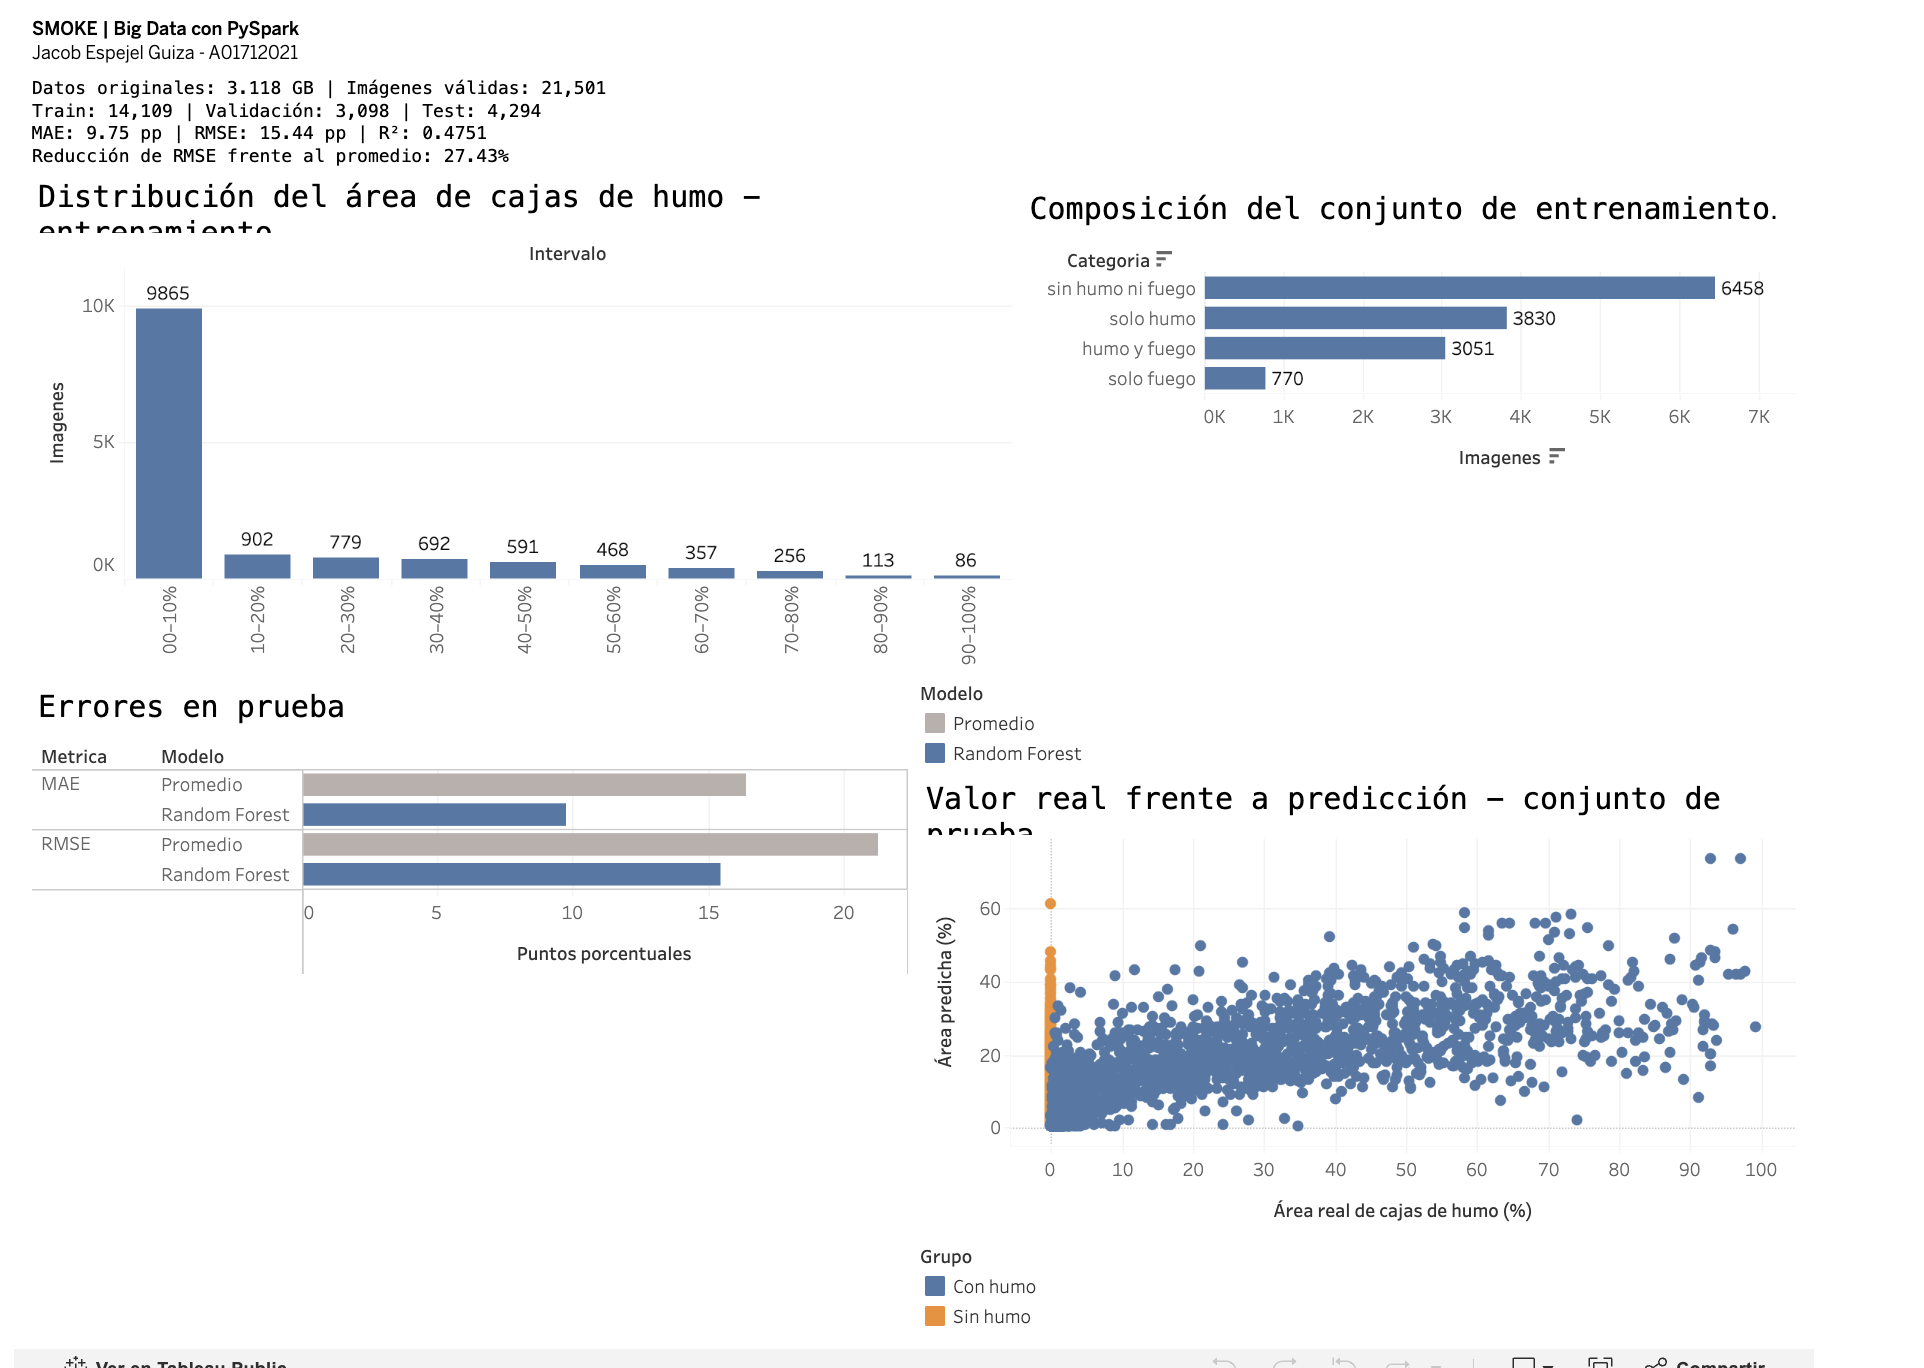

## 11. Síntesis de resultados, evidencia y conclusiones

### 11.1. Comparación cuantitativa

| Modelo evaluado en test | MAE | RMSE | R² |
|---|---:|---:|---:|
| Media de entrenamiento | 0.164194 | 0.212679 | −0.000247 |
| Random Forest, profundidad 10, seleccionado con CV | 0.097519 | 0.154336 | 0.473269 |

Las métricas están en escala de 0 a 1. El error absoluto medio equivale a **9.75 puntos porcentuales** y el RMSE a **15.43 puntos porcentuales** del marco. El bosque reduce el RMSE del predictor constante en **27.43%**. La mejora indica que las características aportan información predictiva frente a una media constante, aunque deja errores relevantes sin resolver.

### 11.2. Evidencias de ejecución

Las salidas conservadas acreditan la prueba técnica del ambiente, el inventario de 3.118 GB, la validación de clases y etiquetas, la reanudación auditada de Parquet, las particiones oficiales, la exploración del entrenamiento, los folds y la selección de CrossValidator, las métricas de test y las predicciones. Las tablas y gráficas permanecen junto al código y a su interpretación.

Los metadatos de la sesión registran **79.847 s** para la celda de reanudación, compactación y auditoría; **474.546 s** para la celda de selección con CV; y **11.064 s** para la evaluación. Son tiempos de celdas completas, no mediciones aisladas de cada algoritmo. El primero corresponde a una reanudación y no al costo de extraer todos los píxeles desde cero.

### 11.3. Eficiencia y alcance del procesamiento

El flujo combina procesamiento por particiones, características compactas, almacenamiento Parquet y persistencia para reutilizar datos entre acciones. El ajuste secuencial de candidatos con `parallelism=1` controla la demanda concurrente de la VM y `collectSubModels=False` evita conservar todos los submodelos de validación. Los resúmenes se calculan antes de llevar tablas derivadas al controlador.

La ejecución utiliza una sola VM con `local[2]`. Las anotaciones se procesan en el controlador y algunas operaciones de unión, agrupación y ventana pueden causar shuffle. Las decisiones implementadas reducen trabajo redundante, pero los registros disponibles no constituyen un benchmark comparativo ni demuestran escalabilidad multinodo. Esta distinción delimita lo que la evidencia permite concluir sobre eficiencia.

### 11.4. Limitaciones de los datos y del modelo

Las cajas incluyen fondo y no describen una máscara precisa de humo. Las estadísticas manuales pueden confundir humo con nubes o neblina y pierden parte de la estructura visual. La dispersión y los casos individuales muestran subestimación de varias áreas grandes y predicciones positivas sobre escenas sin humo.

La ausencia de duplicados exactos no elimina el riesgo de escenas parecidas en distintas particiones. Sin identificadores confiables de cámara o secuencia no puede garantizarse una evaluación independiente por escena. La superioridad frente al baseline no acredita utilidad como sistema de vigilancia o alarma de seguridad.

### 11.5. Conclusión

Se integró un flujo de Big Data con datos originales de más de 1 GB, auditoría de calidad, procesamiento de imágenes con Spark, un Pipeline de MLlib, selección mediante validación cruzada, evaluación independiente y comunicación visual de resultados. El Random Forest seleccionado superó al promedio de entrenamiento, pero sus errores dependen de la presencia de humo y del área objetivo. El valor del proyecto reside tanto en cuantificar esa mejora como en documentar sus límites mediante resultados verificables.

## 12. Referencias

- Dataset seleccionado: [Smoke Fire Detection YOLO](https://www.kaggle.com/datasets/sayedgamal99/smoke-fire-detection-yolo).
- Proyecto de origen de los datos: [D-Fire Dataset](https://gaia-solutions-on-demand.github.io/DFireDataset/).
- Apache Spark 4.0.5: [RDD, evaluación diferida y persistencia](https://spark.apache.org/docs/4.0.5/rdd-programming-guide.html).
- Apache Spark 4.0.5: [Random Forest para regresión](https://spark.apache.org/docs/4.0.5/ml-classification-regression.html#random-forest-regression).
- Apache Spark 4.0.5: [selección de modelos y validación cruzada](https://spark.apache.org/docs/4.0.5/ml-tuning.html).
- Apache Spark 4.0.5: [RegressionEvaluator](https://spark.apache.org/docs/4.0.5/api/python/reference/api/pyspark.ml.evaluation.RegressionEvaluator.html).
